# FedVocabHAR WISDM Phase 2D

## Subject-balanced multi-prototype geometry repair

Phase 2C showed that the frozen SSL-Full embedding supports linear separation but not a single global centroid per activity. Phase 2D keeps that encoder fixed and tests whether multimodal, subject-balanced prototype banks repair the geometry required by federated vocabulary integration.

Prototype policy selection uses known activities from development subjects only through leave-one-subject-out evaluation. Evaluation labels and integration-subject novel labels remain sealed until the selected policy is frozen. Current final results remain exploratory because these evaluation subjects informed the sequence of Phase 2 experiments.


In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
from dataclasses import dataclass,asdict
from pathlib import Path
import json,random,warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score,precision_recall_fscore_support,confusion_matrix
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')

@dataclass(frozen=True)
class Config:
    project:str='/content/drive/MyDrive/FedVocabHAR'
    seed:int=42
    development_subjects:tuple=tuple(range(1635,1642))
    integration_subjects:tuple=tuple(range(1643,1648))
    evaluation_subjects:tuple=tuple(range(1648,1651))
    known_activities:tuple=('F','G','H','I','K')
    novel_activities:tuple=('L','M','O','P','Q','S')
    dev_per_subject_activity:int=150
    final_per_subject_activity:int=300
    diagonal_shrinkage:float=.25
    loso_std_gate:float=.10
    known_accuracy_gate:float=.55
    known_macro_f1_gate:float=.50
    known_i_f1_gate:float=.40
    novel_macro_f1_gate:float=.65
    novel_l_f1_gate:float=.40
    combined_macro_f1_gate:float=.45

CFG=Config();PROJECT=Path(CFG.project);P0=PROJECT/'artifacts'/'phase0';P2B=PROJECT/'artifacts'/'phase2b';P2C=PROJECT/'artifacts'/'phase2c'
OUT=PROJECT/'artifacts'/'phase2d';OUT.mkdir(parents=True,exist_ok=True)
CACHE=P0/'wisdm_watch_accel_w128_s64.npz';ENCODER_CKPT=P2B/'inception_ssl_full.pt';P2C_DECISION=P2C/'phase2c_decision.json'
assert CACHE.exists() and ENCODER_CKPT.exists() and P2C_DECISION.exists()
assert json.loads(P2C_DECISION.read_text())['selected_fusion']=='full_only'
assert not set(CFG.evaluation_subjects)&(set(CFG.development_subjects)|set(CFG.integration_subjects))

def seed_all(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)
seed_all(CFG.seed);DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:',DEVICE);print(json.dumps(asdict(CFG),indent=2))


device: cuda
{
  "project": "/content/drive/MyDrive/FedVocabHAR",
  "seed": 42,
  "development_subjects": [
    1635,
    1636,
    1637,
    1638,
    1639,
    1640,
    1641
  ],
  "integration_subjects": [
    1643,
    1644,
    1645,
    1646,
    1647
  ],
  "evaluation_subjects": [
    1648,
    1649,
    1650
  ],
  "known_activities": [
    "F",
    "G",
    "H",
    "I",
    "K"
  ],
  "novel_activities": [
    "L",
    "M",
    "O",
    "P",
    "Q",
    "S"
  ],
  "dev_per_subject_activity": 150,
  "final_per_subject_activity": 300,
  "diagonal_shrinkage": 0.25,
  "loso_std_gate": 0.1,
  "known_accuracy_gate": 0.55,
  "known_macro_f1_gate": 0.5,
  "known_i_f1_gate": 0.4,
  "novel_macro_f1_gate": 0.65,
  "novel_l_f1_gate": 0.4,
  "combined_macro_f1_gate": 0.45
}


## Load the frozen SSL-Full representation

The encoder, input normalization, and checkpoint are identical to the selected Phase 2C representation. Only prototype construction, aggregation, and distance are allowed to change.


In [3]:
d=np.load(CACHE);x=d['x'].astype(np.float32);subjects=d['subject'].astype(int);activities=d['activity'].astype(str)

class InceptionBlock(nn.Module):
    def __init__(self,cin,width=32):
        super().__init__();self.bottleneck=nn.Conv1d(cin,width,1,bias=False)
        self.branches=nn.ModuleList([nn.Conv1d(width,width,k,padding=k//2,bias=False) for k in (9,19,39)])
        self.pool=nn.Sequential(nn.MaxPool1d(3,stride=1,padding=1),nn.Conv1d(cin,width,1,bias=False));self.bn=nn.BatchNorm1d(width*4)
    def forward(self,q):
        z=self.bottleneck(q);return F.relu(self.bn(torch.cat([b(z) for b in self.branches]+[self.pool(q)],1)))

class InceptionEncoder(nn.Module):
    def __init__(self,cin,dim,n_domains):
        super().__init__();self.block1=InceptionBlock(cin,32);self.block2=InceptionBlock(128,32)
        self.skip=nn.Conv1d(cin,128,1,bias=False);self.bn=nn.BatchNorm1d(128)
        self.project=nn.Sequential(nn.Linear(128,128),nn.ReLU(),nn.Linear(128,dim))
        self.decoder=nn.Conv1d(128,cin,1);self.domain=nn.Sequential(nn.Linear(dim,64),nn.ReLU(),nn.Linear(64,n_domains))
    def forward(self,q):
        seq=F.relu(self.bn(self.block2(self.block1(q))+self.skip(q)));return F.normalize(self.project(seq.mean(-1)),dim=1)

def safe_load(path):
    try:return torch.load(path,map_location='cpu',weights_only=False)
    except TypeError:return torch.load(path,map_location='cpu')

ck=safe_load(ENCODER_CKPT);cin=4 if ck['spec']['magnitude'] else 3;n_domains=ck['state_dict']['domain.2.weight'].shape[0]
model=InceptionEncoder(cin,int(ck['config']['embedding_dim']),n_domains).to(DEVICE);model.load_state_dict(ck['state_dict']);model.eval()
xyz=(x-np.asarray(ck['xyz_mean'],dtype=np.float32))/np.asarray(ck['xyz_std'],dtype=np.float32)
mag=np.sqrt((x*x).sum(1,keepdims=True));mag=(mag-np.asarray(ck['mag_mean'],dtype=np.float32))/np.asarray(ck['mag_std'],dtype=np.float32)
model_input=np.concatenate([xyz,mag],1).astype(np.float32)
emb=[]
with torch.no_grad():
    for start in range(0,len(x),512):emb.append(model(torch.from_numpy(model_input[start:start+512]).to(DEVICE)).cpu().numpy())
embeddings=np.concatenate(emb).astype(np.float32)
print('frozen embeddings:',embeddings.shape,'checkpoint epoch:',ck['best_epoch'])


frozen embeddings: (19704, 64) checkpoint epoch: 8


## Predeclared prototype policies

- **Single centroid:** Phase 2C reference.
- **Subject bank:** one class prototype per source subject, aggregated by minimum or top-two mean distance.
- **K-means bank:** two or three modes per class.
- **Medoid bank:** K-means modes projected to real training examples for outlier resistance.
- **Shrinkage diagonal distance:** pooled within-class feature variance with 25% shrinkage toward an isotropic metric.

All classes receive the same policy and maximum number of prototypes. No activity-specific tuning is permitted.


In [4]:
POLICIES={
 'single_cosine':{'bank':'single','k':1,'aggregate':'min','metric':'cosine'},
 'subject_min_cosine':{'bank':'subject','k':0,'aggregate':'min','metric':'cosine'},
 'subject_top2_cosine':{'bank':'subject','k':0,'aggregate':'top2','metric':'cosine'},
 'kmeans2_cosine':{'bank':'kmeans','k':2,'aggregate':'min','metric':'cosine'},
 'kmeans3_cosine':{'bank':'kmeans','k':3,'aggregate':'min','metric':'cosine'},
 'medoid3_cosine':{'bank':'medoid','k':3,'aggregate':'min','metric':'cosine'},
 'subject_top2_diag':{'bank':'subject','k':0,'aggregate':'top2','metric':'diag'},
 'kmeans3_diag':{'bank':'kmeans','k':3,'aggregate':'min','metric':'diag'}}

known_to_index={a:i for i,a in enumerate(CFG.known_activities)}
all_activities=CFG.known_activities+CFG.novel_activities;all_to_index={a:i for i,a in enumerate(all_activities)}

def limited_by_group(subject_set,activity_set,per_group,seed):
    rng=np.random.default_rng(seed);out=[]
    for subject in subject_set:
        for activity in activity_set:
            idx=np.where((subjects==subject)&(activities==activity))[0]
            if len(idx)>per_group:idx=rng.choice(idx,per_group,replace=False)
            out.extend(idx.tolist())
    return np.asarray(out,dtype=int)

def unit(z):return z/(np.linalg.norm(z,axis=1,keepdims=True)+1e-12)

def make_bank(z,y,source_subjects,labels,spec):
    bank={}
    for label in labels:
        q=z[y==label];s=source_subjects[y==label]
        if spec['bank']=='single':centers=q.mean(0,keepdims=True)
        elif spec['bank']=='subject':centers=np.asarray([q[s==subject].mean(0) for subject in sorted(set(s)) if np.any(s==subject)])
        else:
            k=min(int(spec['k']),len(q));km=KMeans(n_clusters=k,n_init=10,random_state=CFG.seed).fit(q);centers=km.cluster_centers_
            if spec['bank']=='medoid':
                centers=np.asarray([q[np.argmin(((q-center)**2).sum(1))] for center in centers])
        bank[label]=unit(centers) if spec['metric']=='cosine' else centers
    return bank

def classify_policy(train_e,train_y,train_subjects,test_e,test_y,labels,spec):
    scaler=StandardScaler().fit(train_e);ztr=scaler.transform(train_e);zte=scaler.transform(test_e)
    if spec['metric']=='cosine':ztr=unit(ztr);zte=unit(zte);variance=None
    else:
        residual=[]
        for label in labels:
            q=ztr[train_y==label];residual.append(q-q.mean(0,keepdims=True))
        raw_var=np.concatenate(residual).var(0)+1e-4
        variance=(1-CFG.diagonal_shrinkage)*raw_var+CFG.diagonal_shrinkage*np.ones_like(raw_var)
    bank=make_bank(ztr,train_y,train_subjects,labels,spec);class_dist=[]
    for label in labels:
        p=bank[label]
        if spec['metric']=='cosine':dist=1-zte@p.T
        else:dist=((zte[:,None,:]-p[None,:,:])**2/variance[None,None,:]).mean(2)
        if spec['aggregate']=='top2':score=np.sort(dist,axis=1)[:,:min(2,dist.shape[1])].mean(1)
        else:score=dist.min(1)
        class_dist.append(score)
    class_dist=np.stack(class_dist,1);pred=np.asarray(labels)[class_dist.argmin(1)]
    f1s=precision_recall_fscore_support(test_y,pred,labels=labels,zero_division=0)[2]
    return {'accuracy':float(accuracy_score(test_y,pred)),'macro_f1':float(np.mean(f1s)),'pred':pred,'per_class_f1':f1s,
            'mean_margin':float(np.mean(np.partition(class_dist,1,axis=1)[:,1]-np.min(class_dist,axis=1))),
            'prototype_count':int(sum(len(v) for v in bank.values()))}


## Development-only policy selection

Each policy is evaluated on seven leave-one-subject-out folds using known activities only. The score rewards macro-F1, activity-I F1, accuracy, and worst-subject performance while penalizing cross-subject variability:

`score = 0.60 × macro-F1 + 0.25 × I-F1 + 0.10 × accuracy + 0.05 × worst-subject macro-F1 − 0.10 × SD`


In [5]:
dev_idx=limited_by_group(CFG.development_subjects,CFG.known_activities,CFG.dev_per_subject_activity,CFG.seed+1)
dev_y=np.asarray([known_to_index[a] for a in activities[dev_idx]]);fold_rows=[];selection_rows=[]
for name,spec in POLICIES.items():
    rows=[]
    for held in CFG.development_subjects:
        test=subjects[dev_idx]==held;train=~test
        m=classify_policy(embeddings[dev_idx][train],dev_y[train],subjects[dev_idx][train],embeddings[dev_idx][test],dev_y[test],list(range(len(CFG.known_activities))),spec)
        row={'policy':name,'held_subject':held,'accuracy':m['accuracy'],'macro_f1':m['macro_f1'],
             'i_f1':float(m['per_class_f1'][known_to_index['I']]),'mean_margin':m['mean_margin'],'prototype_count':m['prototype_count']}
        rows.append(row);fold_rows.append(row)
    f=pd.DataFrame(rows);summary={'policy':name,'accuracy':f.accuracy.mean(),'macro_f1':f.macro_f1.mean(),
      'macro_f1_std':f.macro_f1.std(ddof=0),'worst_subject_macro_f1':f.macro_f1.min(),'i_f1':f.i_f1.mean(),
      'mean_margin':f.mean_margin.mean(),'mean_prototype_count':f.prototype_count.mean()}
    summary['selection_score']=.60*summary['macro_f1']+.25*summary['i_f1']+.10*summary['accuracy']+.05*summary['worst_subject_macro_f1']-.10*summary['macro_f1_std']
    selection_rows.append(summary)
folds=pd.DataFrame(fold_rows);selection=pd.DataFrame(selection_rows).sort_values('selection_score',ascending=False)
SELECTED_POLICY=str(selection.iloc[0].policy);folds.to_csv(OUT/'phase2d_loso_folds.csv',index=False);selection.to_csv(OUT/'phase2d_selection_results.csv',index=False)
print('selected policy:',SELECTED_POLICY);display(selection.round(4))


selected policy: kmeans3_diag


,policy,accuracy,macro_f1,macro_f1_std,worst_subject_macro_f1,i_f1,mean_margin,mean_prototype_count,selection_score
7,kmeans3_diag,0.3807,0.3276,0.1672,0.1076,0.3465,0.2262,15.0,0.3099
5,medoid3_cosine,0.3711,0.2842,0.0951,0.0884,0.4065,0.0775,15.0,0.3042
0,single_cosine,0.3320,0.2617,0.1223,0.0565,0.4551,0.0749,5.0,0.2946
1,subject_min_cosine,0.3566,0.2953,0.1735,0.0847,0.3698,0.0553,30.0,0.2922
4,kmeans3_cosine,0.3742,0.2997,0.1083,0.0958,0.2764,0.0706,15.0,0.2803
2,subject_top2_cosine,0.3119,0.2374,0.1494,0.0374,0.3357,0.0836,30.0,0.2445
6,subject_top2_diag,0.2909,0.2214,0.1470,0.0399,0.3238,0.4198,30.0,0.2302
3,kmeans2_cosine,0.2989,0.2488,0.1335,0.0153,0.2517,0.0494,10.0,0.2295


## Frozen exploratory final evaluation

After selection, each predeclared policy is evaluated with the same known and oracle combined-vocabulary protocol. Integration novel labels are used only to construct oracle novel prototype banks after policy selection.


In [6]:
known_train_idx=limited_by_group(CFG.development_subjects,CFG.known_activities,CFG.final_per_subject_activity,CFG.seed+10)
novel_train_idx=limited_by_group(CFG.integration_subjects,CFG.novel_activities,CFG.final_per_subject_activity,CFG.seed+11)
oracle_train_idx=np.concatenate([known_train_idx,novel_train_idx])
eval_known_idx=np.where(np.isin(subjects,CFG.evaluation_subjects)&np.isin(activities,CFG.known_activities))[0]
eval_novel_idx=np.where(np.isin(subjects,CFG.evaluation_subjects)&np.isin(activities,CFG.novel_activities))[0]
eval_all_idx=np.concatenate([eval_known_idx,eval_novel_idx])
known_train_y=np.asarray([known_to_index[a] for a in activities[known_train_idx]]);eval_known_y=np.asarray([known_to_index[a] for a in activities[eval_known_idx]])
oracle_train_y=np.asarray([all_to_index[a] for a in activities[oracle_train_idx]]);eval_all_y=np.asarray([all_to_index[a] for a in activities[eval_all_idx]])

result_rows=[];class_rows=[];confusion_rows=[]
for name,spec in POLICIES.items():
    known=classify_policy(embeddings[known_train_idx],known_train_y,subjects[known_train_idx],embeddings[eval_known_idx],eval_known_y,list(range(len(CFG.known_activities))),spec)
    oracle=classify_policy(embeddings[oracle_train_idx],oracle_train_y,subjects[oracle_train_idx],embeddings[eval_all_idx],eval_all_y,list(range(len(all_activities))),spec)
    novel_true=eval_all_y[len(eval_known_idx):];novel_pred=oracle['pred'][len(eval_known_idx):];novel_labels=[all_to_index[a] for a in CFG.novel_activities]
    novel_f1=precision_recall_fscore_support(novel_true,novel_pred,labels=novel_labels,zero_division=0)[2]
    result_rows.append({'policy':name,'selected_on_development':name==SELECTED_POLICY,'known_accuracy':known['accuracy'],'known_macro_f1':known['macro_f1'],
      'known_i_f1':float(known['per_class_f1'][known_to_index['I']]),'known_mean_margin':known['mean_margin'],
      'oracle_novel_macro_f1':float(np.mean(novel_f1)),'oracle_l_f1':float(novel_f1[0]),'oracle_combined_macro_f1':oracle['macro_f1'],
      'oracle_mean_margin':oracle['mean_margin'],'known_prototype_count':known['prototype_count'],'oracle_prototype_count':oracle['prototype_count']})
    for a,f in zip(CFG.known_activities,known['per_class_f1']):class_rows.append({'policy':name,'probe':'known','activity':a,'f1':float(f)})
    for a,f in zip(CFG.novel_activities,novel_f1):class_rows.append({'policy':name,'probe':'oracle_novel','activity':a,'f1':float(f)})
    cm=confusion_matrix(eval_all_y,oracle['pred'],labels=list(range(len(all_activities))))
    for i,t in enumerate(all_activities):
        for j,p in enumerate(all_activities):confusion_rows.append({'policy':name,'true_activity':t,'predicted_activity':p,'count':int(cm[i,j])})
results=pd.DataFrame(result_rows);per_class=pd.DataFrame(class_rows);confusions=pd.DataFrame(confusion_rows)
results.to_csv(OUT/'phase2d_final_results.csv',index=False);per_class.to_csv(OUT/'phase2d_per_class_f1.csv',index=False);confusions.to_csv(OUT/'phase2d_oracle_confusions.csv',index=False)
display(results.round(4))


,policy,selected_on_development,known_accuracy,known_macro_f1,known_i_f1,known_mean_margin,oracle_novel_macro_f1,oracle_l_f1,oracle_combined_macro_f1,oracle_mean_margin,known_prototype_count,oracle_prototype_count
0,single_cosine,False,0.3879,0.3287,0.2134,0.0983,0.7110,0.2162,0.2978,0.2410,5,11
1,subject_min_cosine,False,0.4339,0.4116,0.2808,0.0740,0.7508,0.3103,0.5569,0.1115,35,65
2,subject_top2_cosine,False,0.5042,0.4666,0.3442,0.0933,0.7557,0.1768,0.5803,0.1331,35,65
3,kmeans2_cosine,False,0.5200,0.4902,0.4458,0.0917,0.7090,0.2136,0.5474,0.1328,10,22
4,kmeans3_cosine,False,0.5164,0.4869,0.4410,0.0978,0.7419,0.2946,0.5445,0.0991,15,33
5,medoid3_cosine,False,0.4691,0.4631,0.3030,0.0859,0.7171,0.2723,0.5320,0.1022,15,33
6,subject_top2_diag,False,0.5042,0.4720,0.3636,0.5151,0.7450,0.2032,0.5655,0.4742,35,65
7,kmeans3_diag,True,0.4642,0.4383,0.4518,0.4049,0.7275,0.3399,0.5308,0.3823,15,33


## Evaluation-subject stability and visuals


,subject,known_accuracy,known_macro_f1,known_i_f1,combined_macro_f1
0,1648,0.3491,0.2800,0.3210,0.4622
1,1649,0.4473,0.4023,0.4681,0.4774
2,1650,0.5964,0.5687,0.5273,0.6204


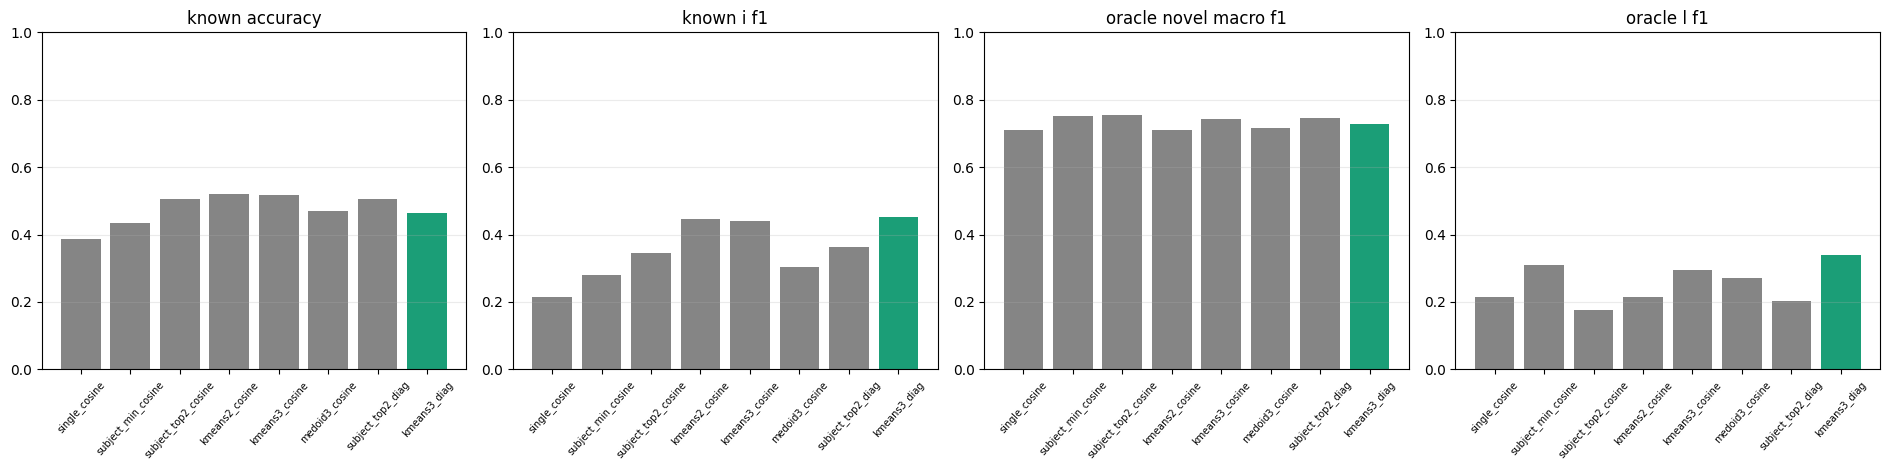

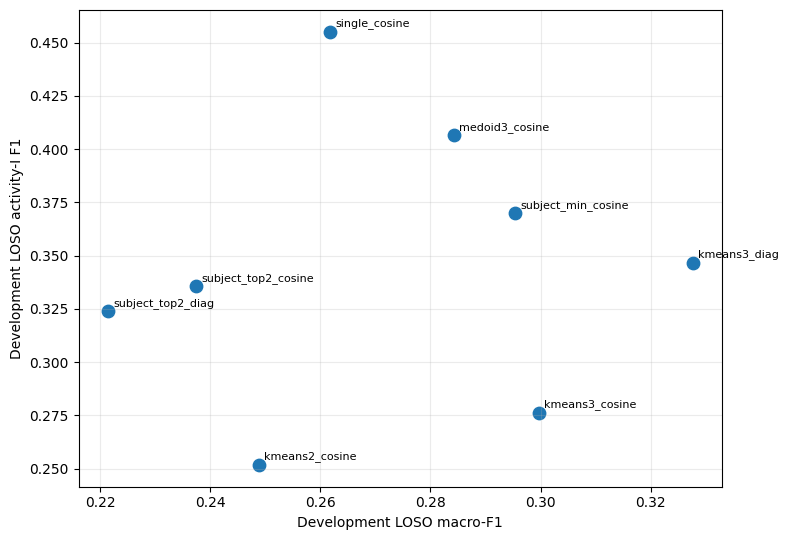

In [7]:
selected_spec=POLICIES[SELECTED_POLICY];subject_rows=[]
for held in CFG.evaluation_subjects:
    ki=eval_known_idx[subjects[eval_known_idx]==held];ai=eval_all_idx[subjects[eval_all_idx]==held]
    ky=np.asarray([known_to_index[a] for a in activities[ki]]);ay=np.asarray([all_to_index[a] for a in activities[ai]])
    km=classify_policy(embeddings[known_train_idx],known_train_y,subjects[known_train_idx],embeddings[ki],ky,list(range(len(CFG.known_activities))),selected_spec)
    am=classify_policy(embeddings[oracle_train_idx],oracle_train_y,subjects[oracle_train_idx],embeddings[ai],ay,list(range(len(all_activities))),selected_spec)
    subject_rows.append({'subject':held,'known_accuracy':km['accuracy'],'known_macro_f1':km['macro_f1'],'known_i_f1':float(km['per_class_f1'][known_to_index['I']]),'combined_macro_f1':am['macro_f1']})
subject_results=pd.DataFrame(subject_rows);subject_results.to_csv(OUT/'phase2d_evaluation_subjects.csv',index=False);display(subject_results.round(4))

fig,axes=plt.subplots(1,4,figsize=(19,4.8));metrics=['known_accuracy','known_i_f1','oracle_novel_macro_f1','oracle_l_f1']
for ax,metric in zip(axes,metrics):
    colors=['#1b9e77' if p==SELECTED_POLICY else '#858585' for p in results.policy]
    ax.bar(results.policy,results[metric],color=colors);ax.set_title(metric.replace('_',' '));ax.tick_params(axis='x',rotation=48,labelsize=7);ax.set_ylim(0,1);ax.grid(axis='y',alpha=.25)
fig.tight_layout();fig.savefig(OUT/'phase2d_policy_comparison.png',dpi=180,bbox_inches='tight');plt.show()

fig,ax=plt.subplots(figsize=(8,5.5));ax.scatter(selection.macro_f1,selection.i_f1,s=80)
for row in selection.itertuples():ax.annotate(row.policy,(row.macro_f1,row.i_f1),xytext=(4,4),textcoords='offset points',fontsize=8)
ax.set_xlabel('Development LOSO macro-F1');ax.set_ylabel('Development LOSO activity-I F1');ax.grid(alpha=.25)
fig.tight_layout();fig.savefig(OUT/'phase2d_development_geometry.png',dpi=180,bbox_inches='tight');plt.show()


## Decision gates and deployable prototype policy


In [8]:
selected=results[results.policy==SELECTED_POLICY].iloc[0];seldev=selection[selection.policy==SELECTED_POLICY].iloc[0]
gates={
 'G1_phase2c_encoder_frozen':True,
 'G2_selected_only_on_development_known_labels':bool(selected.selected_on_development),
 'G3_cross_subject_variance':bool(seldev.macro_f1_std<=CFG.loso_std_gate),
 'G4_known_accuracy':bool(selected.known_accuracy>=CFG.known_accuracy_gate),
 'G5_known_macro_f1':bool(selected.known_macro_f1>=CFG.known_macro_f1_gate),
 'G6_known_I_f1':bool(selected.known_i_f1>=CFG.known_i_f1_gate),
 'G7_novel_macro_f1':bool(selected.oracle_novel_macro_f1>=CFG.novel_macro_f1_gate),
 'G8_novel_L_f1':bool(selected.oracle_l_f1>=CFG.novel_l_f1_gate),
 'G9_combined_macro_f1':bool(selected.oracle_combined_macro_f1>=CFG.combined_macro_f1_gate),
 'G10_artifacts_complete':bool(len(selection)==len(POLICIES) and len(results)==len(POLICIES) and len(subject_results)==len(CFG.evaluation_subjects))}
engineering_pass=bool(all(gates.values()))

def native(v):
    if isinstance(v,(np.bool_,bool)):return bool(v)
    if isinstance(v,(np.floating,float)):return float(v)
    if isinstance(v,(np.integer,int)):return int(v)
    return v
policy_file={'selected_policy':SELECTED_POLICY,'policy_spec':POLICIES[SELECTED_POLICY],
 'preprocessing':'StandardScaler fitted on available prototype-training embeddings; unit normalization for cosine policies.',
 'diagonal_shrinkage':CFG.diagonal_shrinkage,'development_selection':{k:native(v) for k,v in seldev.to_dict().items()}}
(OUT/'phase2d_selected_prototype_policy.json').write_text(json.dumps(policy_file,indent=2))
decision={'phase':'Phase 2D','selected_policy':SELECTED_POLICY,'selected_policy_spec':POLICIES[SELECTED_POLICY],
 'selection':{k:native(v) for k,v in seldev.to_dict().items()},'selected_results':{k:native(v) for k,v in selected.to_dict().items()},
 'gates':gates,'engineering_pass':engineering_pass,'rerun_phase1c_exploratory':engineering_pass,
 'confirmatory_claim_allowed':False,'requires_independent_dataset_confirmation':True,
 'evaluation_status':'Exploratory because the current evaluation subjects informed prior Phase 2 design decisions. Policy selection used development known labels only.',
 'config':asdict(CFG)}
(OUT/'phase2d_decision.json').write_text(json.dumps(decision,indent=2));print(json.dumps(decision,indent=2))


{
  "phase": "Phase 2D",
  "selected_policy": "kmeans3_diag",
  "selected_policy_spec": {
    "bank": "kmeans",
    "k": 3,
    "aggregate": "min",
    "metric": "diag"
  },
  "selection": {
    "policy": "kmeans3_diag",
    "accuracy": 0.38071146245059284,
    "macro_f1": 0.3275910396854305,
    "macro_f1_std": 0.1671749420136931,
    "worst_subject_macro_f1": 0.10755863272349994,
    "i_f1": 0.34652247163864036,
    "mean_margin": 0.22615892955634212,
    "mean_prototype_count": 15.0,
    "selection_score": 0.3099168254007834
  },
  "selected_results": {
    "policy": "kmeans3_diag",
    "selected_on_development": true,
    "known_accuracy": 0.46424242424242423,
    "known_macro_f1": 0.4382624527436481,
    "known_i_f1": 0.45180722891566266,
    "known_mean_margin": 0.4049088656902313,
    "oracle_novel_macro_f1": 0.7274719113520968,
    "oracle_l_f1": 0.33992094861660077,
    "oracle_combined_macro_f1": 0.5307947727902316,
    "oracle_mean_margin": 0.3823187053203583,
    "known_pro

In [9]:
report=f"""# FedVocabHAR Phase 2D Decision Report

## Decision

**Selected prototype policy:** {SELECTED_POLICY}

**Engineering gates passed:** {engineering_pass}

**Exploratory Phase 1C rerun:** {decision['rerun_phase1c_exploratory']}

## Development geometry

- LOSO macro-F1: {seldev.macro_f1:.4f}
- LOSO subject SD: {seldev.macro_f1_std:.4f}
- LOSO activity-I F1: {seldev.i_f1:.4f}
- Worst-subject macro-F1: {seldev.worst_subject_macro_f1:.4f}

## Exploratory frozen diagnostics

- Known accuracy: {selected.known_accuracy:.4f}
- Known macro-F1: {selected.known_macro_f1:.4f}
- Known activity-I F1: {selected.known_i_f1:.4f}
- Novel macro-F1: {selected.oracle_novel_macro_f1:.4f}
- Novel activity-L F1: {selected.oracle_l_f1:.4f}
- Combined macro-F1: {selected.oracle_combined_macro_f1:.4f}

## Gates

"""
for name,value in gates.items():report+=f'- {name}: **{value}**\n'
report+='\nThese results are exploratory. An independent dataset or preregistered external evaluation is required before making confirmatory paper claims.\n'
(OUT/'FedVocabHAR_Phase2D_Decision_Report.md').write_text(report);print(report);print('saved outputs to',OUT)


# FedVocabHAR Phase 2D Decision Report

## Decision

**Selected prototype policy:** kmeans3_diag

**Engineering gates passed:** False

**Exploratory Phase 1C rerun:** False

## Development geometry

- LOSO macro-F1: 0.3276
- LOSO subject SD: 0.1672
- LOSO activity-I F1: 0.3465
- Worst-subject macro-F1: 0.1076

## Exploratory frozen diagnostics

- Known accuracy: 0.4642
- Known macro-F1: 0.4383
- Known activity-I F1: 0.4518
- Novel macro-F1: 0.7275
- Novel activity-L F1: 0.3399
- Combined macro-F1: 0.5308

## Gates

- G1_phase2c_encoder_frozen: **True**
- G2_selected_only_on_development_known_labels: **True**
- G3_cross_subject_variance: **False**
- G4_known_accuracy: **False**
- G5_known_macro_f1: **False**
- G6_known_I_f1: **True**
- G7_novel_macro_f1: **True**
- G8_novel_L_f1: **False**
- G9_combined_macro_f1: **True**
- G10_artifacts_complete: **True**

These results are exploratory. An independent dataset or preregistered external evaluation is required before making confirmatory p

## Interpretation

- If every gate passes, use the selected prototype policy in an exploratory rerun of the unchanged Phase 1C admission and replay sequence.
- If novel prototypes pass but known/I fail, multi-modality alone does not resolve subject drift; do not proceed to integration.
- If medoid or subject-bank policies win, retain client provenance in the federated prototype registry rather than averaging all client modes into one centroid.
- Confirm the frozen encoder and selected policy on an independent HAR dataset before using the result as evidence in the manuscript.
